# Tox21 graph dataset EDA

This notebook computes graph-level size statistics and label coverage from the cleaned Phase 1 dataset. It checks the graph cache against the cleaned CSV, preserves the repository row-order contract, and saves figures to report_phase2/figures.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

from src.config import ENDPOINTS, ROOT
from src.data import load_clean
from src.dl.graph import ATOM_TYPES
from src.dl.run import get_graphs
from src.dl.split_io import load_split_named

FIG_DIR = ROOT / "report_phase2" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")

/Users/gllama/Desktop/Sem 5/Molecular-Toxicity-Prediction/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Load data and summarize molecular graphs

A molecule's number of bonds is counted once per undirected bond, while the graph representation stores each bond in both directions. Atom categories use the graph featurizer's nine named elements plus its other bucket.

In [2]:
df, Y = load_clean()
graphs = get_graphs()
assert len(df) == len(graphs) == Y.shape[0]
assert all(int(g.idx) == i for i, g in enumerate(graphs))

atom_counts = np.asarray([g.x.shape[0] for g in graphs], dtype=int)
bond_counts = np.asarray([g.edge_index.shape[1] // 2 for g in graphs], dtype=int)
atom_type_counts = np.zeros(len(ATOM_TYPES) + 1, dtype=np.int64)
for g in graphs:
    atom_type_counts += g.x[:, :len(ATOM_TYPES) + 1].sum(dim=0).cpu().numpy().round().astype(np.int64)

graph_summary = pd.DataFrame({
    "Statistic": ["Molecules", "Atoms per molecule", "Bonds per molecule"],
    "Mean": [len(graphs), atom_counts.mean(), bond_counts.mean()],
    "Median": [len(graphs), np.median(atom_counts), np.median(bond_counts)],
    "Minimum": [len(graphs), atom_counts.min(), bond_counts.min()],
    "Maximum": [len(graphs), atom_counts.max(), bond_counts.max()],
})
display(graph_summary)
print(f"Atom feature width: {graphs[0].x.shape[1]}; bond feature width: {graphs[0].edge_attr.shape[1]}")


,Statistic,Mean,Median,Minimum,Maximum
0,Molecules,7709.000000,7709.0,7709,7709
1,Atoms per molecule,18.280711,16.0,1,132
2,Bonds per molecule,19.025295,16.0,0,145


Atom feature width: 33; bond feature width: 6


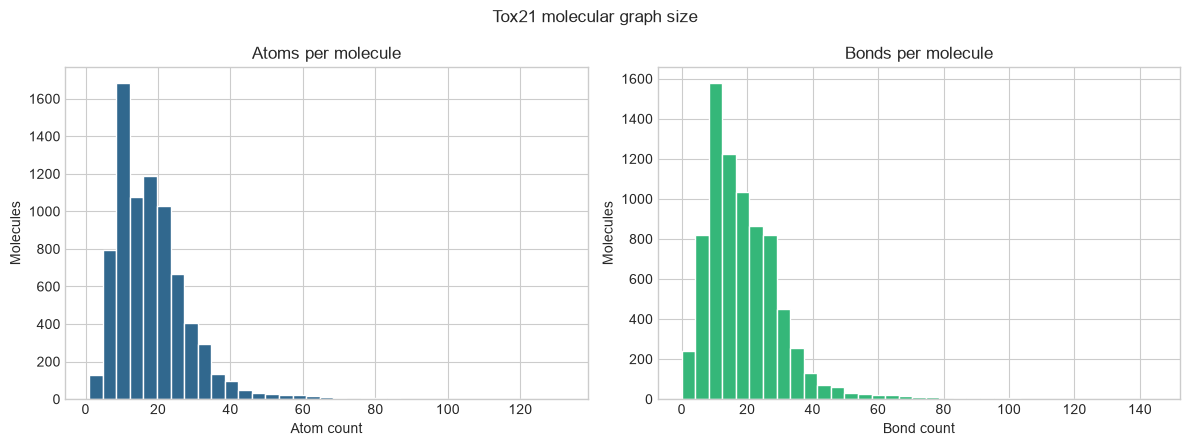

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(atom_counts, bins=35, color="#31688e", edgecolor="white")
axes[0].set(title="Atoms per molecule", xlabel="Atom count", ylabel="Molecules")
axes[1].hist(bond_counts, bins=35, color="#35b779", edgecolor="white")
axes[1].set(title="Bonds per molecule", xlabel="Bond count", ylabel="Molecules")
fig.suptitle("Tox21 molecular graph size")
fig.tight_layout()
fig.savefig(FIG_DIR / "graph_size_distributions.png", dpi=180, bbox_inches="tight")
plt.show()


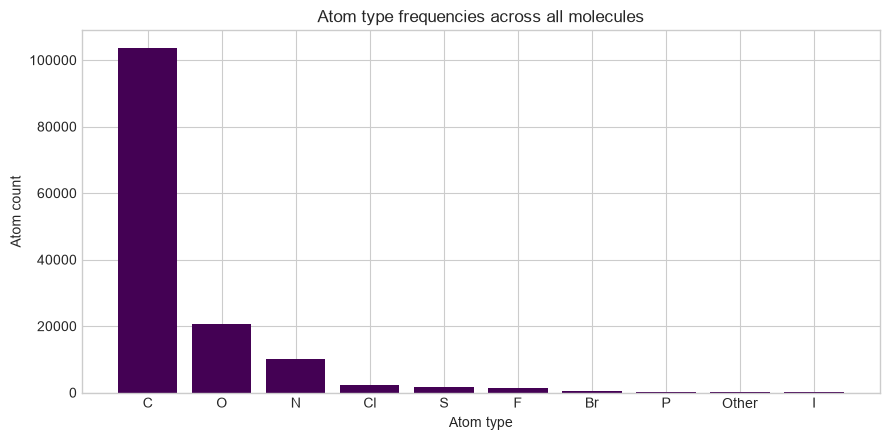

,Atom type,Count
0,C,103717
2,O,20704
1,N,10160
5,Cl,2198
3,S,1703
4,F,1389
6,Br,379
8,P,263
9,Other,218
7,I,195


In [4]:
atom_labels = list(ATOM_TYPES) + ["Other"]
order = np.argsort(atom_type_counts)[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(np.asarray(atom_labels, dtype=object)[order], atom_type_counts[order], color="#440154")
ax.set(title="Atom type frequencies across all molecules", xlabel="Atom type", ylabel="Atom count")
fig.tight_layout()
fig.savefig(FIG_DIR / "graph_atom_type_frequencies.png", dpi=180, bbox_inches="tight")
plt.show()
display(pd.DataFrame({"Atom type": atom_labels, "Count": atom_type_counts}).sort_values("Count", ascending=False))

## Endpoint positive rates and missing labels

Positive rate is calculated only among observed labels. Missing fraction is the share of all molecules with an unobserved label for that assay.

,Endpoint,Labeled,Positive,Positive rate (labeled),Missing,Missing fraction
0,NR-AR,7141,304,4.257%,568,7.368%
1,NR-AR-LBD,6652,235,3.533%,1057,13.711%
2,NR-AhR,6444,763,11.840%,1265,16.409%
3,NR-Aromatase,5718,286,5.002%,1991,25.827%
4,NR-ER,6103,781,12.797%,1606,20.833%
5,NR-ER-LBD,6851,343,5.007%,858,11.130%
6,NR-PPAR-gamma,6354,185,2.912%,1355,17.577%
7,SR-ARE,5739,915,15.944%,1970,25.555%
8,SR-ATAD5,6962,261,3.749%,747,9.690%
9,SR-HSE,6374,364,5.711%,1335,17.317%


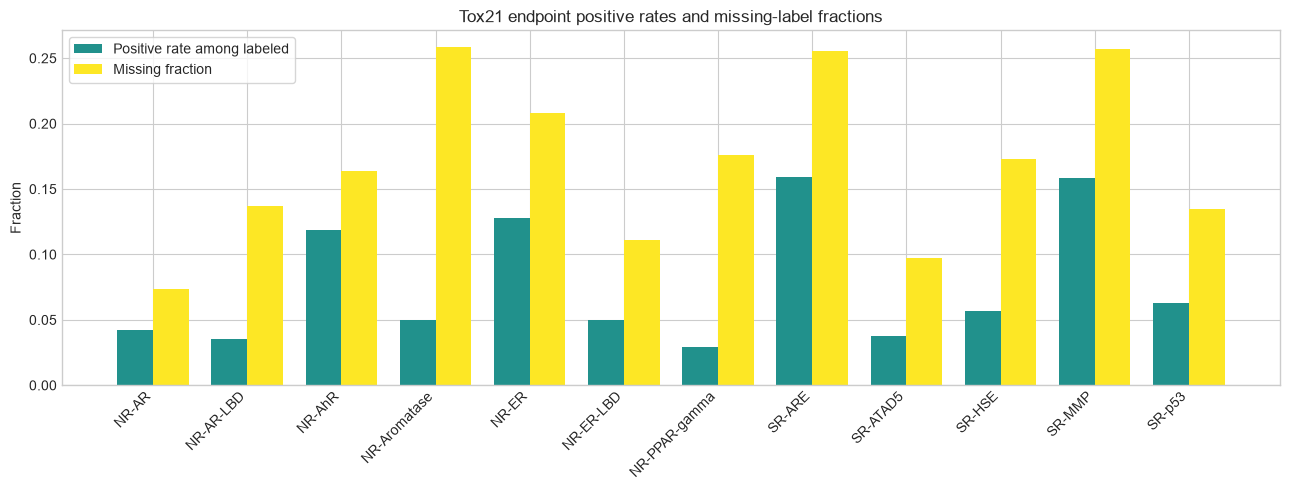

In [5]:
n_molecules = len(df)
observed = np.isfinite(Y)
positive = (Y == 1) & observed
endpoint_stats = pd.DataFrame({
    "Endpoint": ENDPOINTS,
    "Labeled": observed.sum(axis=0).astype(int),
    "Positive": positive.sum(axis=0).astype(int),
    "Positive rate (labeled)": positive.sum(axis=0) / np.maximum(observed.sum(axis=0), 1),
    "Missing": (~observed).sum(axis=0).astype(int),
    "Missing fraction": (~observed).sum(axis=0) / n_molecules,
})
display(endpoint_stats.style.format({
    "Positive rate (labeled)": "{:.3%}", "Missing fraction": "{:.3%}"
}))
x = np.arange(len(ENDPOINTS))
fig, ax = plt.subplots(figsize=(13, 5))
width = 0.38
ax.bar(x - width/2, endpoint_stats["Positive rate (labeled)"], width, label="Positive rate among labeled", color="#21918c")
ax.bar(x + width/2, endpoint_stats["Missing fraction"], width, label="Missing fraction", color="#fde725")
ax.set_xticks(x, ENDPOINTS, rotation=45, ha="right")
ax.set_ylabel("Fraction")
ax.set_title("Tox21 endpoint positive rates and missing-label fractions")
ax.legend(frameon=True)
fig.tight_layout()
fig.savefig(FIG_DIR / "graph_endpoint_positive_missing_rates.png", dpi=180, bbox_inches="tight")
plt.show()


## Labeled observations in scaffold partitions

Counts are computed with the canonical scaffold split indices and the same label matrix used to build the graph cache.

,Endpoint,train,val,test
0,NR-AR,5745,701,695
1,NR-AR-LBD,5437,607,608
2,NR-AhR,5244,601,599
3,NR-Aromatase,4708,520,490
4,NR-ER,5030,535,538
5,NR-ER-LBD,5567,634,650
6,NR-PPAR-gamma,5234,560,560
7,SR-ARE,4807,469,463
8,SR-ATAD5,5659,660,643
9,SR-HSE,5250,566,558


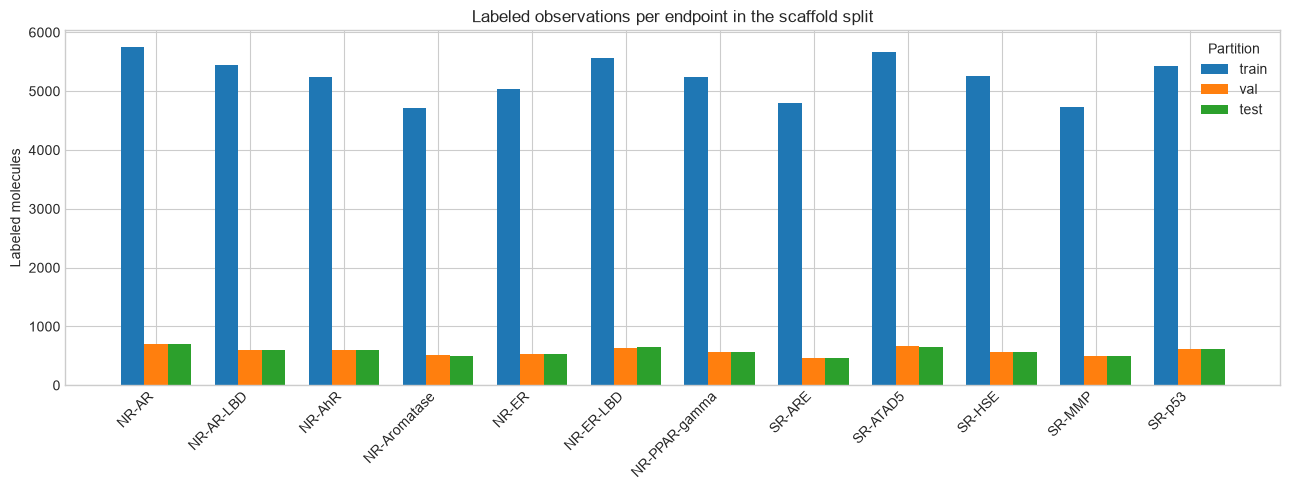

In [6]:
scaffold = load_split_named("scaffold")
split_names = ["train", "val", "test"]
split_labeled = pd.DataFrame({
    "Endpoint": ENDPOINTS,
    **{
        name: np.isfinite(Y[np.asarray(scaffold[name], dtype=int)]).sum(axis=0).astype(int)
        for name in split_names
    },
})
display(split_labeled)
fig, ax = plt.subplots(figsize=(13, 5))
width = 0.25
for j, name in enumerate(split_names):
    ax.bar(x + (j - 1) * width, split_labeled[name], width, label=name)
ax.set_xticks(x, ENDPOINTS, rotation=45, ha="right")
ax.set_ylabel("Labeled molecules")
ax.set_title("Labeled observations per endpoint in the scaffold split")
ax.legend(title="Partition")
fig.tight_layout()
fig.savefig(FIG_DIR / "graph_scaffold_labeled_counts.png", dpi=180, bbox_inches="tight")
plt.show()


## Dataset statistics table for the report

The following LaTeX table is generated from the loaded data and graph objects; no values are manually entered.

In [7]:
summary_rows = [
    ("Molecules", len(graphs)),
    ("Toxicity endpoints", len(ENDPOINTS)),
    ("Atom features per node", int(graphs[0].x.shape[1])),
    ("Bond features per directed edge", int(graphs[0].edge_attr.shape[1])),
    ("Mean atoms per molecule", f"{atom_counts.mean():.2f}"),
    ("Median atoms per molecule", f"{np.median(atom_counts):.0f}"),
    ("Mean bonds per molecule", f"{bond_counts.mean():.2f}"),
    ("Median bonds per molecule", f"{np.median(bond_counts):.0f}"),
    ("Scaffold train / validation / test", " / ".join(str(len(scaffold[k])) for k in split_names)),
    ("Total observed molecule--endpoint labels", int(observed.sum())),
    ("Total missing molecule--endpoint labels", int((~observed).sum())),
]
latex = [
    r"\begin{tabular}{lr}",
    r"\hline",
    r"Statistic & Value \\",
    r"\hline",
]
latex.extend(f"{label} & {value} \\" for label, value in summary_rows)
latex.extend([r"\hline", r"\end{tabular}"])
latex_table = "\n".join(latex)
print(latex_table)


\begin{tabular}{lr}
\hline
Statistic & Value \\
\hline
Molecules & 7709 \
Toxicity endpoints & 12 \
Atom features per node & 33 \
Bond features per directed edge & 6 \
Mean atoms per molecule & 18.28 \
Median atoms per molecule & 16 \
Mean bonds per molecule & 19.03 \
Median bonds per molecule & 16 \
Scaffold train / validation / test & 6167 / 771 / 771 \
Total observed molecule--endpoint labels & 76738 \
Total missing molecule--endpoint labels & 15770 \
\hline
\end{tabular}


### Saved figures

- graph_size_distributions.png
- graph_atom_type_frequencies.png
- graph_endpoint_positive_missing_rates.png
- graph_scaffold_labeled_counts.png

All are written under report_phase2/figures.